This notebook is dedicated to data analysis of the new 1500 datapoints.

In [1]:
# import modules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# read in the dataset
data = pd.read_csv("../../data/results_s18.csv")
data.head()

,zams,xi_1.5,xi_1.75,xi_2.0,xi_2.25,xi_2.5,xi_2.75,xi_3.0,coremass_Si,corerad_Si,coremass_Fe,corerad_Fe,exploded
0,12.00,0.706436,0.301518,0.129584,0.044313,0.025005,0.015826,0.009215,1.593086,2.956980e+08,1.396419,1.483308e+08,False
1,12.01,0.666355,0.287077,0.133169,0.046851,0.026113,0.016529,0.009806,1.606168,3.364827e+08,1.375800,1.399285e+08,False
2,12.02,0.735530,0.321768,0.138306,0.046452,0.025535,0.015812,0.008812,1.560773,2.491711e+08,1.407802,1.529686e+08,False
3,12.03,0.869549,0.393744,0.144617,0.030037,0.016538,0.011069,0.007128,1.565078,2.100526e+08,1.394626,1.331820e+08,False
4,12.04,0.868106,0.360651,0.140825,0.035509,0.019835,0.013299,0.008484,1.550249,2.007662e+08,1.397803,1.335820e+08,True


## Exploring the data

In [3]:
data.describe()

,zams,xi_1.5,xi_1.75,xi_2.0,xi_2.25,xi_2.5,xi_2.75,xi_3.0,coremass_Si,corerad_Si,coremass_Fe,corerad_Fe
count,1500.00000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1.500000e+03,1500.000000,1.500000e+03
mean,19.49500,0.930964,0.630123,0.408150,0.290383,0.230494,0.195667,0.172278,1.778505,2.663883e+08,1.545279,1.668815e+08
std,4.33157,0.088715,0.205549,0.175850,0.131983,0.109460,0.097727,0.090894,0.182486,7.039049e+07,0.107901,2.349305e+07
min,12.00000,0.516052,0.192563,0.117291,0.030037,0.016538,0.011069,0.007128,1.439356,1.645362e+08,1.321014,1.147820e+08
25%,15.74750,0.883969,0.445103,0.243366,0.174235,0.138552,0.108793,0.087929,1.606842,2.220960e+08,1.466979,1.471623e+08
50%,19.49500,0.976634,0.743237,0.419423,0.288420,0.223989,0.189451,0.168639,1.813700,2.635501e+08,1.552984,1.677390e+08
75%,23.24250,0.988885,0.803399,0.526145,0.372444,0.298387,0.258349,0.236235,1.896691,2.904451e+08,1.602705,1.845102e+08
max,26.99000,1.009491,0.871879,0.732267,0.578623,0.459229,0.391543,0.346774,2.172135,7.365772e+08,1.804791,2.270143e+08


In [4]:
# % of stars that exploded
data.exploded.value_counts()/1500

True     0.885333
False    0.114667
Name: exploded, dtype: float64

<AxesSubplot:xlabel='zams', ylabel='Count'>

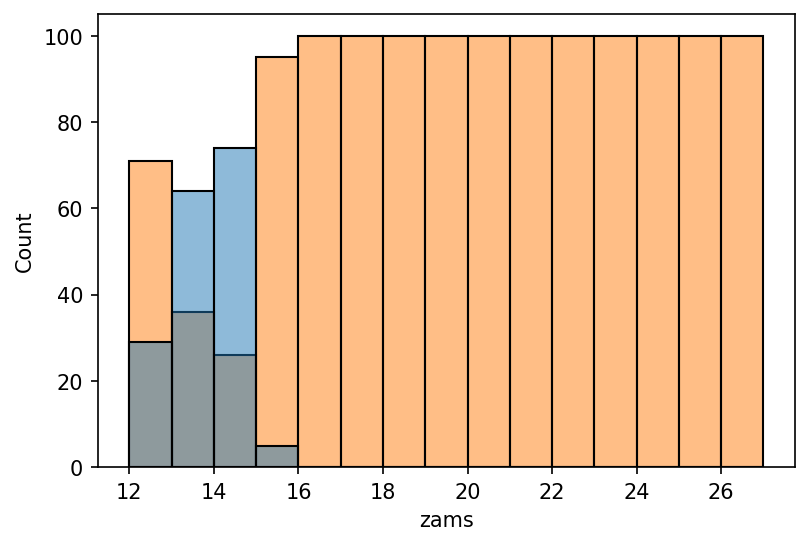

In [10]:
plt.figure(dpi = 150)
sns.histplot(data, x = 'zams', hue = 'exploded', multiple = 'layer', binwidth=1, legend = False)

In [50]:
data.groupby(by = ['exploded']).agg(["mean", "std"])

zams              xi_1.5             xi_1.75            \
               mean       std      mean       std      mean       std   
exploded                                                                
False     13.749767  0.826761  0.828176  0.082980  0.464746  0.086356   
True      20.239111  4.034092  0.944277  0.080351  0.651543  0.206789   

            xi_2.0             xi_2.25            ...    xi_3.0            \
              mean       std      mean       std  ...      mean       std   
exploded                                          ...                       
False     0.251385  0.052792  0.164260  0.047453  ...  0.054401  0.027549   
True      0.428454  0.175995  0.306719  0.130608  ...  0.187546  0.084856   

         coremass_Si              corerad_Si               coremass_Fe  \
                mean       std          mean           std        mean   
exploded                                                                 
False       1.659972  0.091907  3.030131e+08  1.450761e+08    1.488899   
True        1.793857  0.185666  2.616448e+08  5.185068e+07    1.552581   

                      corerad_Fe                
               std          mean           std  
exploded                                        
False     0.069130  1.712510e+08  2.416566e+07  
True      0.109866  1.663155e+08  2.335408e+07  

[2 rows x 24 columns]

### Heat Plot

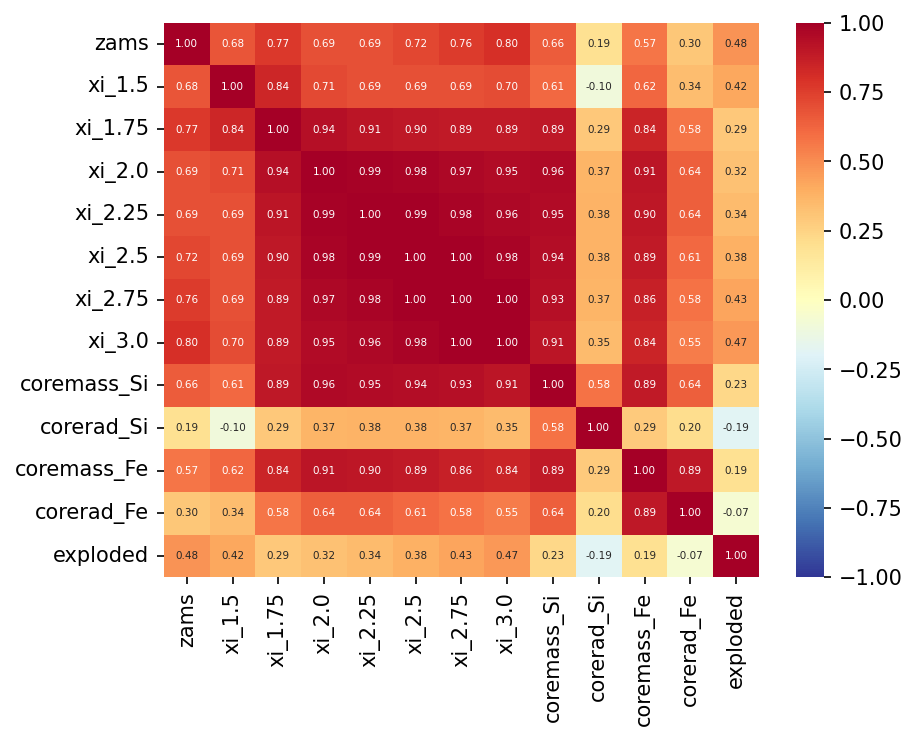

In [17]:
plt.figure(dpi = 150)
sns.heatmap(data.corr(),vmin=-1, vmax=1, annot = True,fmt = ".2f", annot_kws={"size":5}, cmap = "RdYlBu_r")
plt.show()

Some important notes to point out: 
1. No paramenter is strongly coorelated with `explosion`
2. `corerad_Fe` is has a near 0 coorelation with `exploded`
3. There are some multicollinearity issues that come with `xi_#` that will cause overfitting

### Pair Plot

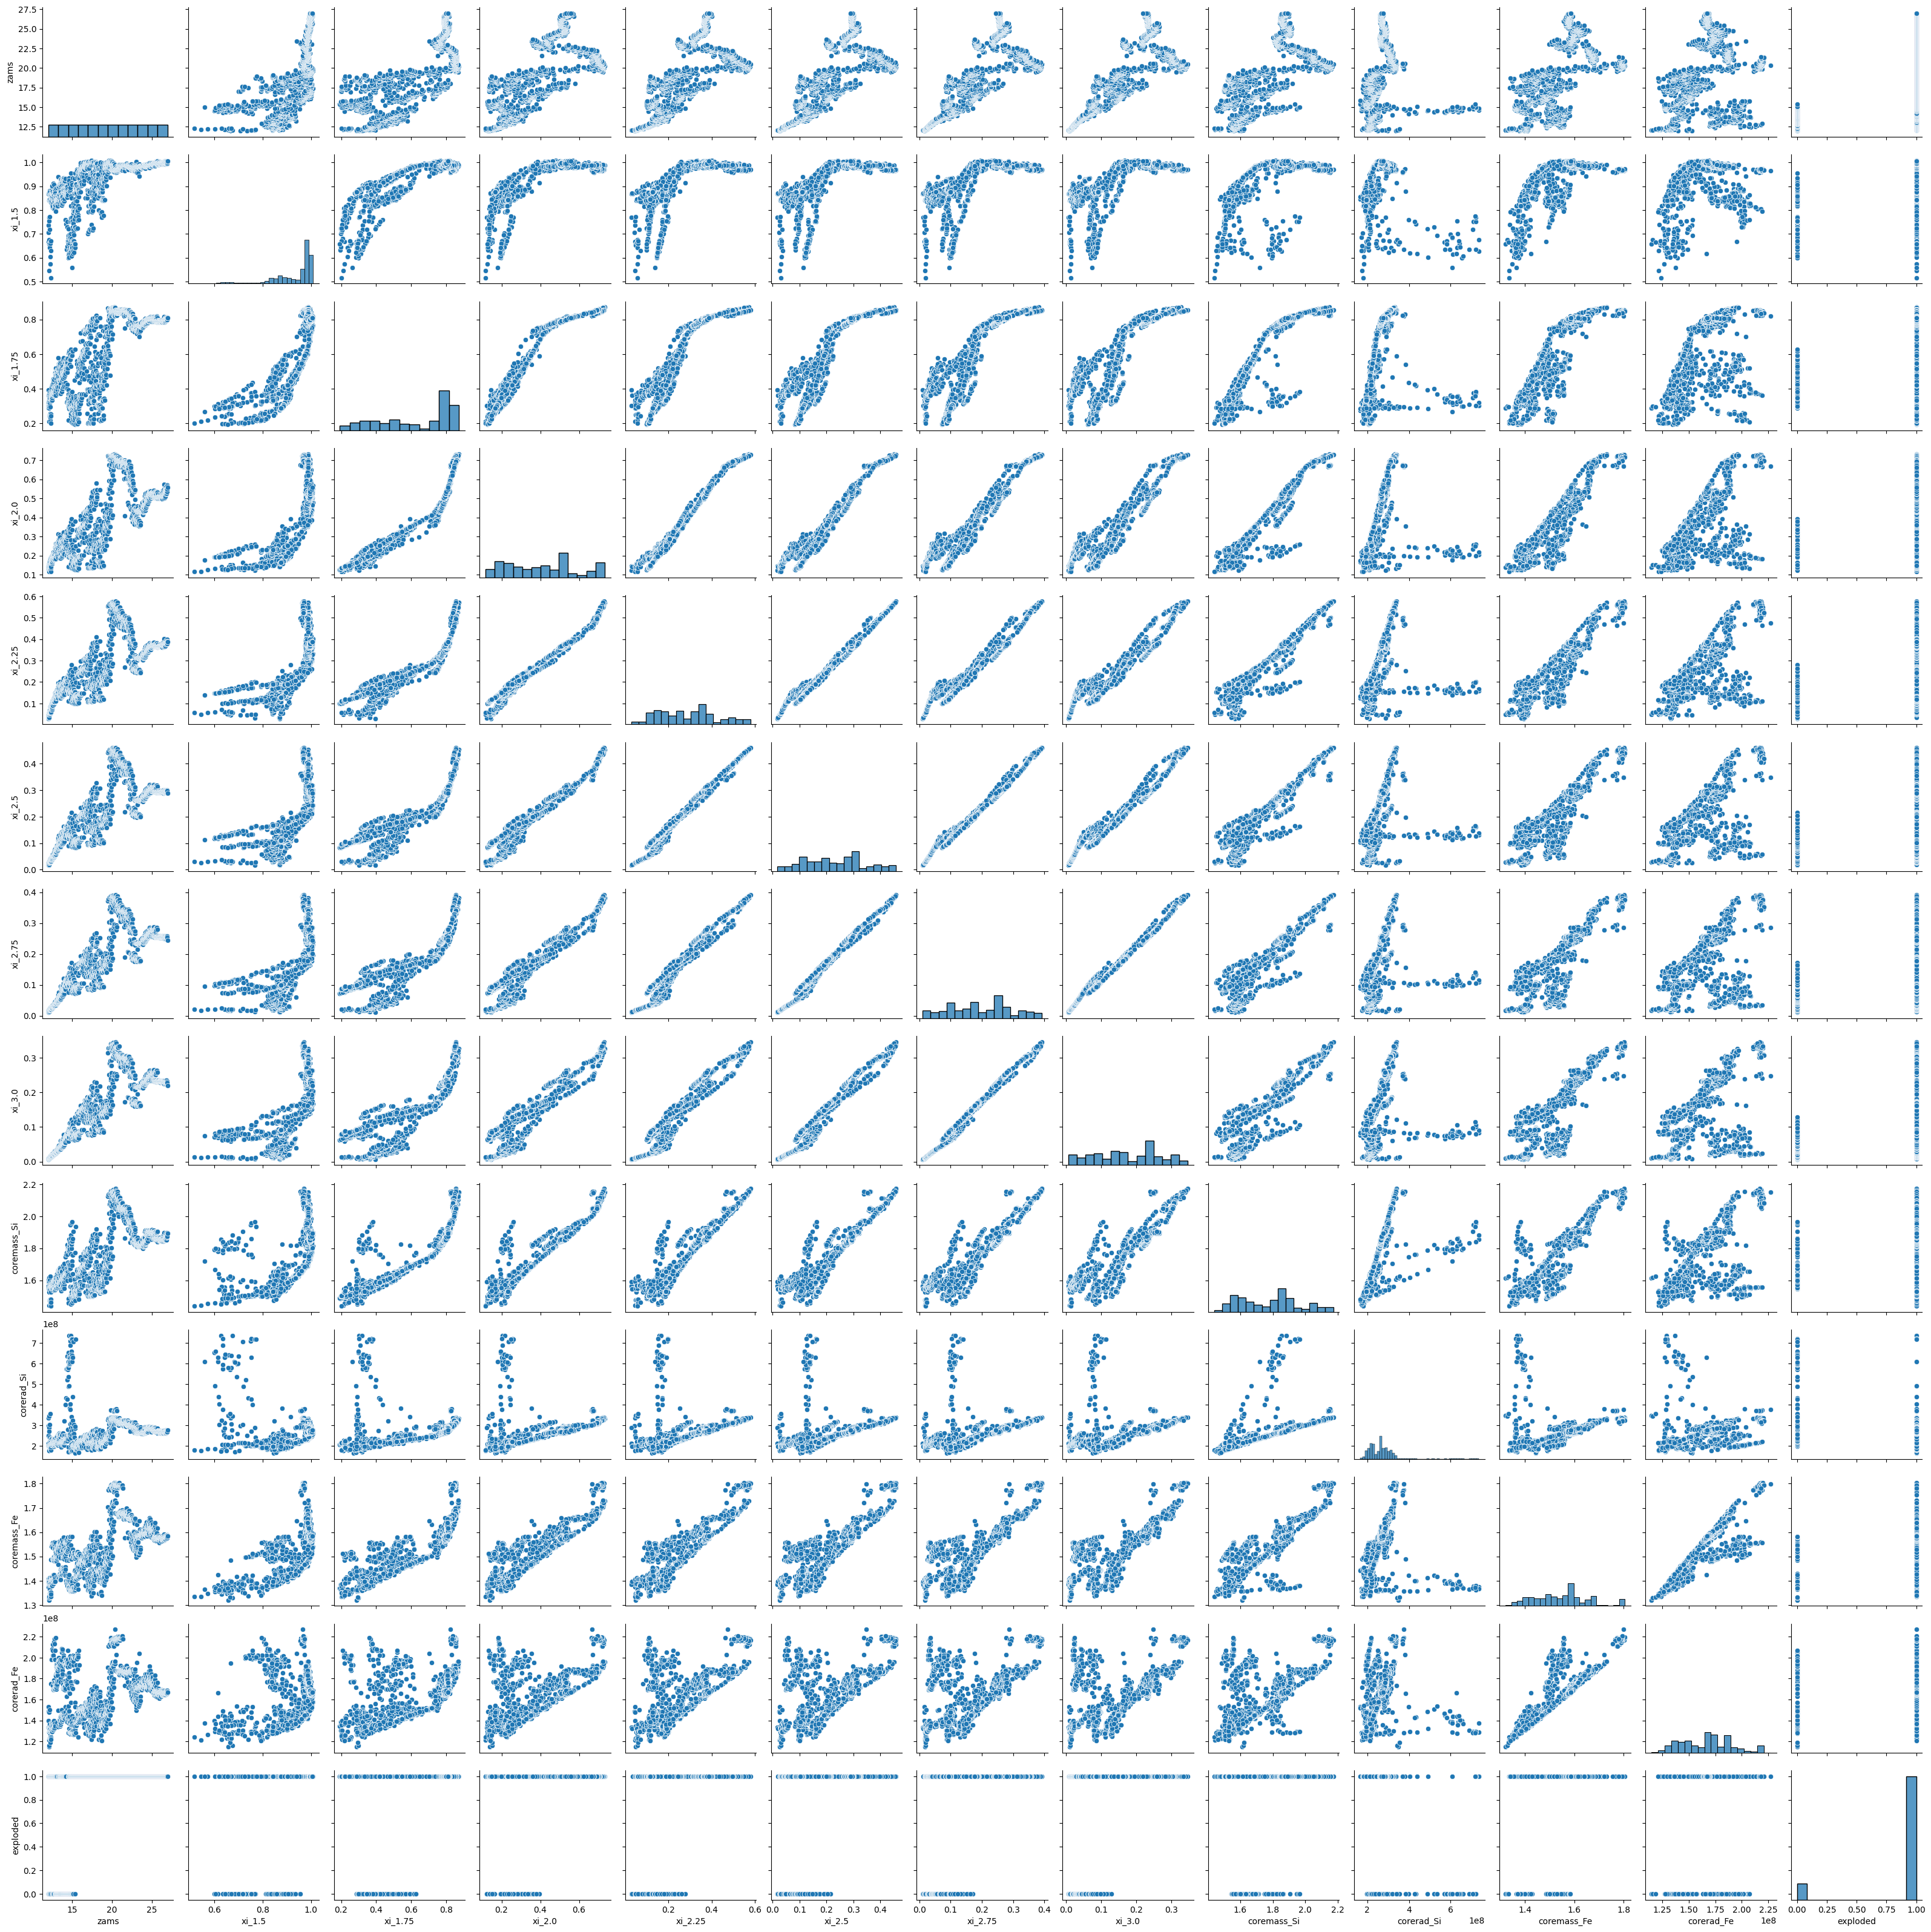

In [18]:
sns.pairplot(data)

<Axes: xlabel='zams', ylabel='coremass_Fe'>

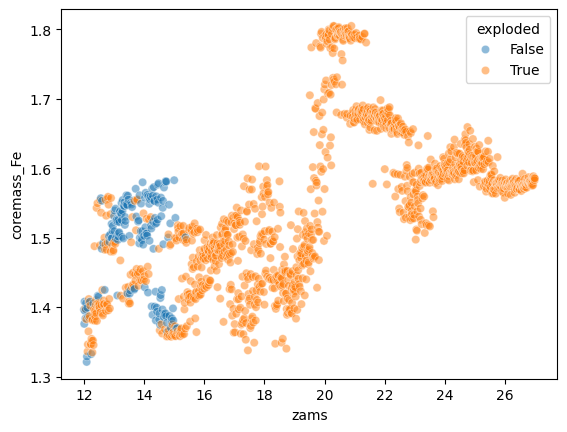

In [37]:
sns.scatterplot(data, x = 'zams', y = 'coremass_Fe', hue = 'exploded', alpha = .5)

## Feature Engineering

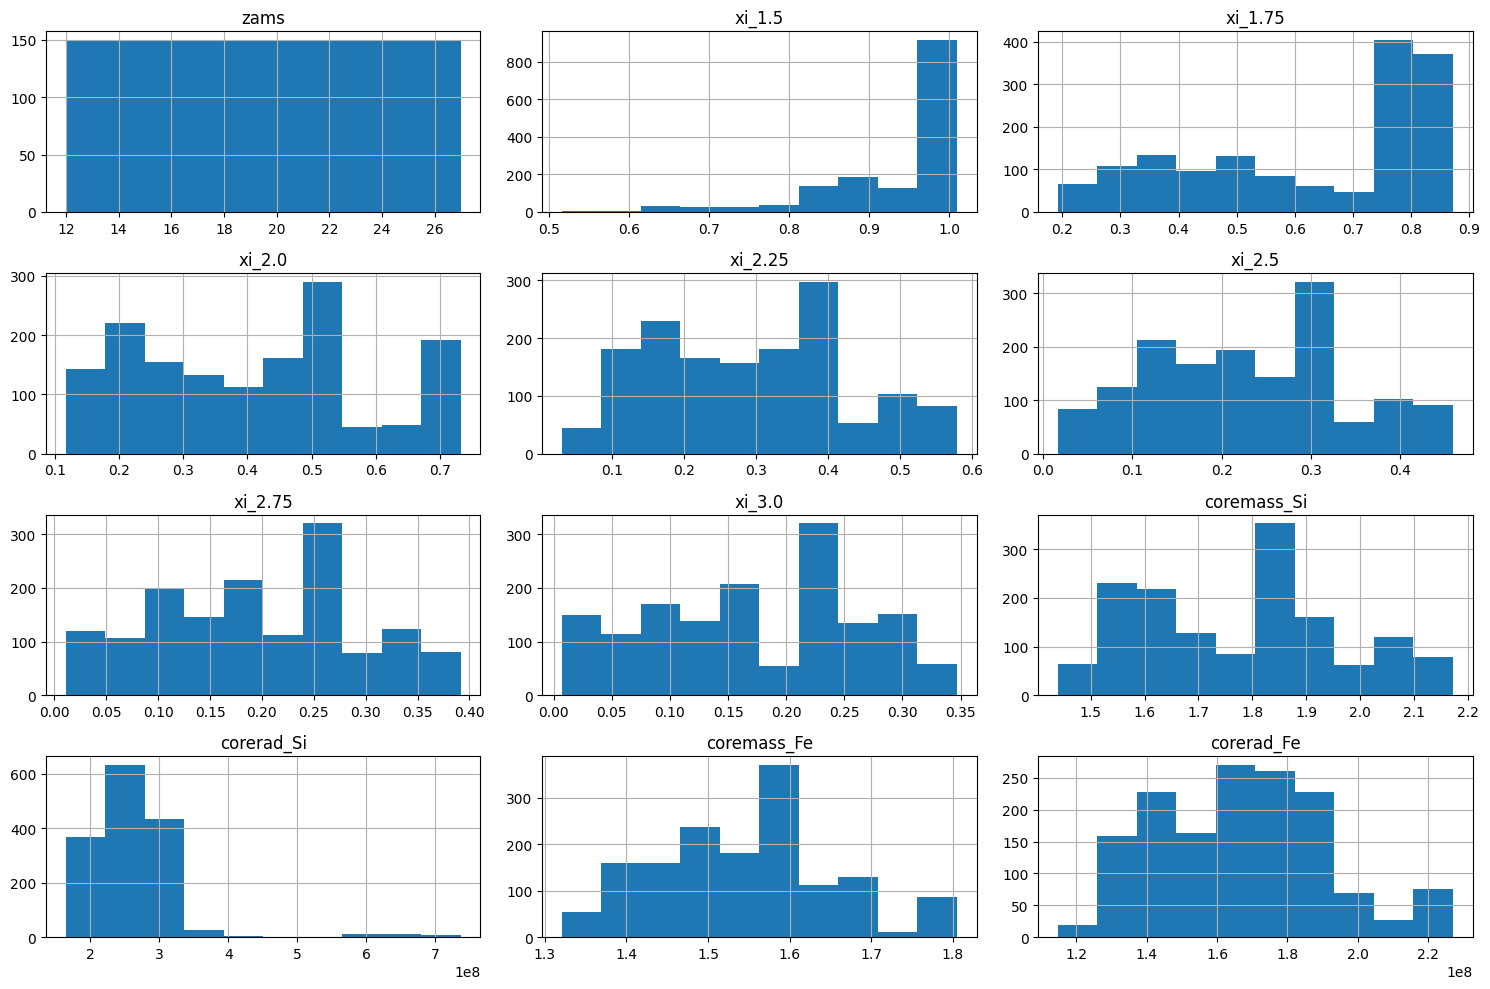

In [5]:
data.hist(figsize = (15,10))

plt.tight_layout()
plt.show()